# T3.3 Leakage: sinusoidal NRCS

**Purpose** (supplements T3.2): which scales of leakage does the correction remove? The NRCS is modulated sinusoidally along azimuth at several wavelengths.
The correction re-estimates the leakage from SCA's own NRCS, which is itself integrated over the beam, so NRCS structure at scales comparable to the beam is
smoothed before the estimate sees it. A dB-linear gradient (T3.2) is unaffected by this smoothing; a sinusoid is not.

**Implementation**
1. SWB California geometry in ground range, with a synthetic azimuth axis long enough for the longest wavelength
2. $\sigma^0(x, r) = \sigma^0_{CMOD5.N}(r)\,10^{\,A \sin(2\pi x / L)/10}$, with amplitude $A$ in dB and wavelength $L$ along azimuth
3. Estimate leakage
4. Correct the leakage with SCA's own NRCS, re-estimated from (a) the speckled NRCS, as in the uncertainty notebooks, and (b) the noise-free NRCS, which isolates the beam smoothing

This notebook performs the test and reports the results for interpretation. No tolerances or pass/fail criteria are applied.

In [1]:
import numpy as np
import xarray as xr
import pandas as pd
from matplotlib import pyplot as plt

from stereoid.oceans.forward_models.cmod5n import cmod5n_forward
from sca_module.readers import create_dataset
from sca_module.dopsca_setup import DopSCAConfig
from sca_module.simulate_L1 import compute_cube_observation_geometry, compute_observations, create_observation_cube, compute_lpf_cube, add_L1_uncertainties, multilook_nrcs_to_grid

plt.rcParams.update({'font.size': 10, 'font.weight' : 'bold'})

## 0 - Parameters

In [2]:
sca = DopSCAConfig()
sca.Lambda = sca.get_wavelength()
# The magic_divider is an unnecessary, but convenient, method to resample the input data to some common sampling.
sca.grid_spacing_target = sca.get_grid_spacing_target(magic_divider=2)

wind_direction_wrt_sensor = 45 # [deg], fixed wind direction w.r.t. the look direction for CMOD5.N
amplitude = 1 # amplitude of the NRCS modulation [dB]
wavelengths = np.array([10, 50, 100, 200]) * 1E3 # along-track wavelength of the modulation [m]

az_extent = 1000E3 # synthetic azimuth extent [m]
grg_extent = slice(590E3, 742E3) # ground range [m], as in the Monte Carlo notebooks

## 1 - Load geometry
Only the incidence angle along ground range of the SWB simulation is used; the azimuth axis is synthetic.

In [3]:
files_cali = [
    '/Users/opodriscoll/Documents/projects/DopSCA MOMS/ATBD/data/SWB_input_California.nc',
    '/Users/opodriscoll/Documents/projects/DopSCA MOMS/ATBD/data/SWB_output_California.nc'
]

simulation = xr.open_mfdataset(files_cali, compat='no_conflicts', engine='netcdf4').sel(sat = 'S1').compute()
sca.magic_offset = sca.get_magic_offset(incidence_min=simulation.inc.min().data)
inc = simulation[sca.var_inc].assign_coords(grg = simulation.grg + sca.magic_offset)

grg = np.arange(grg_extent.start, grg_extent.stop, sca.grid_spacing_target)
az = np.arange(0, az_extent, sca.grid_spacing_target)
inc_deg = np.degrees(inc.interp(grg=grg).data)

# EUMETSAT beam pattern, as in the uncertainty notebooks
beam_SCA = xr.open_dataset('/Users/opodriscoll/Documents/projects/DopSCA MOMS/data/beam_pattern_updated.nc')['beam_sca']

## 2 - NRCS with a sinusoidal modulation along azimuth

In [4]:
sigma0_range = cmod5n_forward(
    v=np.full_like(inc_deg, sca.U),
    phi=np.full_like(inc_deg, wind_direction_wrt_sensor),
    theta=inc_deg,
)

def nrcs_sinusoid(wavelength):
    return sigma0_range[None, :] * 10 ** (amplitude * np.sin(2 * np.pi * az[:, None] / wavelength) / 10)

## 3 - Estimate and correct leakage
As in T3.2: `add_L1_uncertainties` adds speckle to the scatterometer NRCS, the leakage is re-estimated from it after multi-looking onto the input grid,
and subtracted from the incurred leakage. The re-estimate is repeated with the noise-free scatterometer NRCS. All fields are low-pass filtered to the product
resolution, keeping only product cells whose whole footprint is available. The same noise realisation is used for every wavelength.

In [5]:
inc_2d = np.repeat(inc_deg[None, :], len(az), axis=0)
grg_uniform = np.arange(grg.min(), grg.max(), sca.grid_spacing_slant_range_SCA)

def observation_cube(data, var_nrcs):
    data_cube = create_observation_cube(data, sca.az_footprint_cutoff, sca.grid_spacing_target, sca.v_sat_ground, sca.PRF, dropna=False).compute()
    data_cube = compute_cube_observation_geometry(data_cube, sca.dim_az_beam, sca.dim_az_slow_time, sca.dim_range, sca.var_inc, sca.z0, sca.boresight_elevation_angle_scat)
    data_cube = data_cube.transpose(sca.dim_az_slow_time, sca.dim_az_beam, sca.dim_range)
    data_cube['beam'] = beam_SCA.interp(az_beam=data_cube.az_beam, grg=data_cube.grg, method='linear')
    data_cube = compute_observations(data_cube, var_nrcs, sca.var_inc, sca.dim_az_beam, sca.v_sat_orbit, sca.Lambda, sca.T_pp, var_azimuth_angle_wrt_boresight = "az_angle_wrt_boresight_ground")
    return data_cube.transpose(sca.dim_az_slow_time, sca.dim_az_beam, sca.dim_range)

def leakage_with_correction(wavelength):
    nrcs = nrcs_sinusoid(wavelength)
    data = create_dataset(nrcs=nrcs, dop=np.zeros_like(nrcs), inc=inc_2d, grg=grg, az=az, grid_spacing=sca.grid_spacing_target)

    data_cube = observation_cube(data, sca.var_nrcs)
    ds = add_L1_uncertainties(
        ds = data_cube,
        dim_range = sca.dim_range,
        dim_az_beam = sca.dim_az_beam,
        v_sat_orbit = sca.v_sat_orbit,
        U = sca.U,
        sat_height = sca.z0,
        T_pp= sca.T_pp,
        Lambda = sca.Lambda,
        fixed_SCR=None,
        grid_spacing_slant_range=sca.grid_spacing_slant_range_SCA,
        random_state=sca.random_state
    )
    ds = ds[["V_leakage_pulse_rg", "nrcs_scat", "nrcs_scat_speckle"]].interp(grg=grg_uniform, method=sca.interpolator).astype("float32")
    ds = ds.transpose(sca.dim_az_slow_time, sca.dim_range)

    # re-estimate the leakage from SCA's own NRCS, speckled and noise-free, and subtract it from the incurred leakage
    for name, var_nrcs in [("speckled", "nrcs_scat_speckle"), ("noise_free", "nrcs_scat")]:
        data[f"nrcs_{name}"] = multilook_nrcs_to_grid(ds, data, var_nrcs=var_nrcs)
        estimate = observation_cube(data, f"nrcs_{name}")["V_leakage_pulse_rg"].interp(grg=grg_uniform, method=sca.interpolator)
        ds[f"residual_{name}"] = ds["V_leakage_pulse_rg"] - estimate

    fields = ["V_leakage_pulse_rg", "residual_noise_free", "residual_speckled"]
    ds = compute_lpf_cube(
        ds,
        resolution_product= sca.resolution_product,
        fs_x=1 / data_cube.attrs["stride"],
        fs_y=1 / sca.grid_spacing_slant_range_SCA,
        data_2_lpf=fields,
        window=sca.product_averaging_window,
        crop_edges = True,
        min_footprint_coverage = 1, # only product cells whose whole footprint is available
    )
    lpf = ds[[f + "_lpf" for f in fields]]
    return lpf.where(lpf.to_array().notnull().all("variable")) # all fields over the same product cells

corrected = {wavelength: leakage_with_correction(wavelength) for wavelength in wavelengths}

# Results
## Leakage correction
RMS at 50 km over the evaluated product cells, in m/s. The residual from the noise-free NRCS is the leakage the correction cannot see through the beam;
the residual from the speckled NRCS adds the speckle-induced error, as in T3.2.

In [6]:
rms = lambda da: float(np.sqrt((da**2).mean()))
correction = pd.DataFrame(
    {
        "incurred": [rms(ds["V_leakage_pulse_rg_lpf"]) for ds in corrected.values()],
        "residual, noise-free NRCS": [rms(ds["residual_noise_free_lpf"]) for ds in corrected.values()],
        "residual, speckled NRCS": [rms(ds["residual_speckled_lpf"]) for ds in corrected.values()],
    },
    index=pd.Index(wavelengths / 1E3, name="L [km]"),
)
correction["residual / incurred, noise-free"] = correction["residual, noise-free NRCS"] / correction["incurred"]
correction.round(3)

,incurred,"residual, noise-free NRCS","residual, speckled NRCS","residual / incurred, noise-free"
L [km],,,,
10.0,0.361,0.000,1.098,0.000
50.0,5.130,1.737,2.192,0.339
100.0,5.598,0.551,1.253,0.098
200.0,2.907,0.076,1.091,0.026


## Along-track profiles
At 50 km, averaged over ground range.

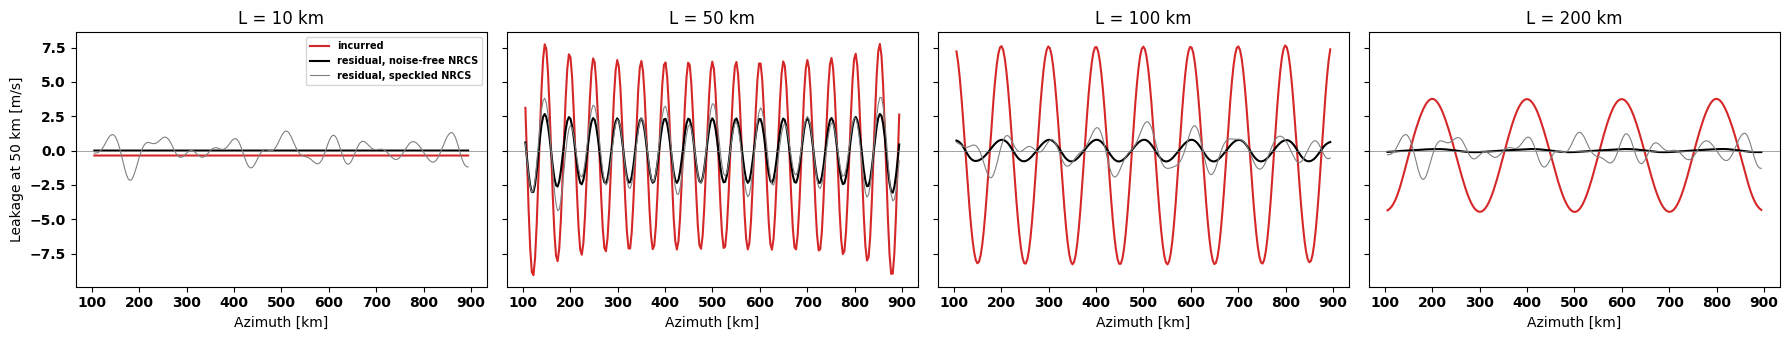

In [7]:
fig, axes = plt.subplots(ncols=len(wavelengths), figsize = (18, 3.5), sharey = True)
for ax, (wavelength, ds) in zip(axes, corrected.items()):
    profiles = ds.mean(sca.dim_range).dropna(sca.dim_az_slow_time)
    x = profiles[sca.dim_az_slow_time] / 1E3
    ax.plot(x, profiles["V_leakage_pulse_rg_lpf"], color = 'C3', label = "incurred")
    ax.plot(x, profiles["residual_noise_free_lpf"], color = 'k', label = "residual, noise-free NRCS")
    ax.plot(x, profiles["residual_speckled_lpf"], color = 'grey', lw = 0.8, label = "residual, speckled NRCS")
    ax.axhline(0, color = 'grey', lw = 0.5)
    ax.set_title(f"L = {wavelength / 1E3:.0f} km")
    ax.set_xlabel("Azimuth [km]")
axes[0].set_ylabel("Leakage at 50 km [m/s]")
axes[0].legend(fontsize = 7)
plt.tight_layout()